# 15 · Generalist Models and the Road to AGI

This is a module of Neural Networks 1002. It assumes the transformer ([module 09 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/09-transformer/)) and the GPT-from-scratch ([module 10 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/10-gpt-from-scratch/)) modules; the earlier modules gave you the parts: neurons, backpropagation, convolutions, attention, reinforcement learning, diffusion, speech and agents. This closing theory module asks what happens when those parts are pooled into **one model for many things**, and how far that road goes. It is deliberately calm: for each claim we separate **what has been measured and published** from **what is speculation**, and we label speculation as such. We give **no dates and no probabilities** for artificial general intelligence (AGI), because nobody has a method that justifies them.

What you will build: a tiny decoder-only transformer that reads **one stream of tokens** mixing an 8×8 image (as 64 tokens) with words, and that uses the **same weights** to classify, caption, generate an image from a caption and complete half an image. You measure each task, compare with single-task models of the same size, and then run a small scaling experiment: five model sizes (four fitted, the largest held out), two seeds, a fitted power law, and an extrapolation to a size we then really train, to see how far such extrapolations can be trusted.

**Contents**

1. One model for everything: turning every modality into tokens
2. Scale and emergent abilities: what scaling laws say and do not say
3. Reasoning: chain of thought, test-time compute, verifiable rewards
4. Agents and tools
5. The physical world: world models and vision-language-action models
6. What is still missing
7. What does "AGI" mean, and why is measuring it hard?
8. Hands-on: one transformer, four tasks
9. Hands-on: a small scaling experiment
10. Scaling alone: arguments for and against
11. Key takeaways, Exercises, References

**Builds on**

| Module | What it gave us | Used here |
|---|---|---|
| [module 09 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/09-transformer/): transformer | attention, causal masks, blocks | the model in section 8 |
| [module 10 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/10-gpt-from-scratch/): LLMs (GPT from scratch) | next-token training, scaling-law section | sections 2, 8, 9 |
| [module 04 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/04-reinforcement-learning/): reinforcement learning | reward, policy, exploration | section 3 (verifiable rewards) |
| [module 01 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/01-rlhf-and-alignment/): RLHF and alignment | preference reward, alignment | sections 3 and 6 |
| [module 11 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/11-vision-beyond-classification/): vision beyond classification | images as grids, embeddings | section 1 |
| [module 14 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/14-agents-and-orchestration/): agents and orchestration | tool loops, supervisors | section 4 |

Related courses: the supervisor and tool-loop idea of section 4 is taught in the [RAG systems course, module 08 "the supervisor model"](https://rag-systems.academy.forwardforecasting.eu/08-the-supervisor-model/) (the course home is [here](https://rag-systems.academy.forwardforecasting.eu/)), and the Python and PyTorch basics used below are in [Python 1001](https://python.academy.forwardforecasting.eu/).

**Where the toy differs from the real systems.** Everything we train has about 30 thousand parameters, sees 1300 tiny images and runs for a few hundred steps on a CPU. Real generalist models have billions of parameters, trillions of tokens of text, images and audio, and months of accelerator time. Our results show the *mechanism* (one token stream, one set of weights) and the *method* (measure, compare, fit), not what a large system can do.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/15_generalist_models_and_agi.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 2 minutes, with a peak memory of about 1.1 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

## 1. One model for everything: turning every modality into tokens

A transformer ([module 09 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/09-transformer/)) does not know what its inputs mean. It maps a sequence of integers (tokens) to embeddings, mixes them with attention, and predicts the next token. So **anything that can be written as a sequence of discrete symbols can share one model**:

| Modality | How it becomes tokens | Published example |
|---|---|---|
| text | subword pieces from a tokenizer | GPT-3 ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)) |
| images | cut into patches, each patch a vector (Vision Transformer, ViT) or a code from a learned codebook (VQ-VAE (vector-quantised variational autoencoder)) | [ViT](https://arxiv.org/abs/2010.11929), [VQ-VAE](https://arxiv.org/abs/1711.00937), [DALL-E](https://arxiv.org/abs/2102.12092) |
| audio | spectrogram frames or codec codes | [Whisper](https://arxiv.org/abs/2212.04356) (see [module 06 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/06-audio-and-video-generation/) and [module 07 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/07-speech-recognition-synthesis-and-voice/)) |
| actions | discretised joint angles, button presses, tool calls | [Gato](https://arxiv.org/abs/2205.06175) |

**Measured and published.** Gato used one transformer with one set of weights to play Atari games, caption images, chat and control a real robot arm, with each modality serialised into the same token stream. Chameleon ([Team, 2024](https://arxiv.org/abs/2405.09818)) trained a single model from scratch on interleaved text and image tokens. CLIP ([Radford et al., 2021](https://arxiv.org/abs/2103.00020)) and Flamingo ([Alayrac et al., 2022](https://arxiv.org/abs/2204.14198)) link a vision encoder to a language model. These systems show that a shared sequence model is *possible* and often *convenient*. They do not show that one model beats a specialist on every task: specialists are still common where accuracy or cost matters.

The recipe in all of them is a **template**: special tokens say which task is asked, and the model continues the sequence. In section 8 the same idea is applied at toy scale:

```
classify : [64 image tokens] <QUESTION> <label>
caption  : [64 image tokens] <CAPTION?> <digit word> <parity> <ink>
generate : <DRAW> <digit word> <parity> <ink> [64 image tokens]
complete : [top 32 image tokens] <FILL> [bottom 32 image tokens]
```

Note what changes between tasks: only the **order** of the same kinds of tokens. This is why one architecture and one loss (predict the next token) can serve all four.

## 2. Scale and emergent abilities: what scaling laws say and do not say

[Module 10 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/10-gpt-from-scratch/) introduced the scaling-law idea. Here is the precise published content.

* **Kaplan et al. (2020)** ([arXiv 2001.08361](https://arxiv.org/abs/2001.08361)) measured that the test loss $L$ of language models falls as a **power law** in the number of parameters $N$, the dataset size $D$ and the compute $C$, when the other factors are not the bottleneck: roughly $L(N) \approx (N_c / N)^{\alpha_N}$, where $N_c$ and $\alpha_N$ (the exponent) are fitted constants. The trends held over several orders of magnitude.
* **Hoffmann et al. (2022)** ([arXiv 2203.15556](https://arxiv.org/abs/2203.15556)), the "Chinchilla" study, re-measured how to split a fixed compute budget between parameters and training tokens and concluded that many large models of the time were **under-trained**: parameters and tokens should grow roughly together.
* **What the laws say**: the *average next-token loss* on a fixed data distribution is smooth and predictable in $N$, $D$ and $C$ within the range measured.
* **What they do not say**: they do not say which *abilities* appear at which loss, they are fitted to past models and are not laws of nature, they assume data of constant quality (and the supply of new human text is finite, see [Villalobos et al., 2022](https://arxiv.org/abs/2211.04325)), and they say nothing about what happens outside the measured range.

**Emergent abilities.** [Wei et al. (2022)](https://arxiv.org/abs/2206.07682) reported tasks whose accuracy sits near chance for small models and then jumps for larger ones. [Schaeffer et al. (2023)](https://arxiv.org/abs/2304.15004) argued that many of these jumps come from the **metric**: an all-or-nothing metric such as exact match turns a smooth improvement in per-token probability into an apparent jump, and with a continuous metric the curves often look smooth. Both papers are measurements; the disagreement is about interpretation. A safe summary is: *loss is smooth and predictable; specific abilities may look sudden or smooth depending on how you score them, and predicting a particular ability from a loss curve is far less reliable than predicting the loss itself.* Section 9 lets you test the first half of that sentence yourself, on a toy.

## 3. Reasoning: chain of thought, test-time compute, verifiable rewards

* **Chain of thought (CoT).** [Wei et al. (2022)](https://arxiv.org/abs/2201.11903) showed that prompting a large model with worked examples that spell out intermediate steps improves accuracy on arithmetic and logic benchmarks. [Kojima et al. (2022)](https://arxiv.org/abs/2205.11916) found that even the instruction "let's think step by step" helps. Extra generated tokens act as working memory: each step conditions the next. [Self-consistency](https://arxiv.org/abs/2203.11171) samples several chains and takes a majority vote.
* **Test-time compute.** Instead of only making the model bigger (training compute), spend more compute at answer time: longer chains, more samples, search. [Snell et al. (2024)](https://arxiv.org/abs/2408.03314) measured that, for some problems, extra test-time compute can substitute for a larger model, and that how to spend it depends on problem difficulty.
* **Training with verifiable rewards.** Where an answer can be **checked automatically** (a maths result, code that passes unit tests), reinforcement learning ([module 04 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/04-reinforcement-learning/)) can use the check as the reward, without a learned preference model ([module 01 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/01-rlhf-and-alignment/)). [DeepSeek-R1](https://arxiv.org/abs/2501.12948) reported that this kind of training makes long self-checking chains appear in the model's outputs.

**Caveats (measured, but narrow).** The gains are largest in domains with a cheap verifier. Written reasoning is not always a faithful account of how the model reached its answer, and the generalisation of these gains to domains without a verifier is an open research question. We mark as *speculation* any statement that verifiable-reward training will carry over to open-ended tasks.

## 4. Agents and tools

[Module 14 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/14-agents-and-orchestration/) builds an agent loop: the model proposes an action (a tool call), a program executes it, the result is appended to the context, and the loop repeats. Two published ideas matter for the generalist picture:

* **Tools as actions in the token stream.** [ReAct](https://arxiv.org/abs/2210.03629) interleaves reasoning text and tool actions; [Toolformer](https://arxiv.org/abs/2302.04761) trains a model to decide when to call a calculator, a search engine or a translator. Calling a tool is just more tokens, which is why the same sequence model can drive it (the Gato idea of section 1).
* **Tools patch weaknesses without retraining**: exact arithmetic, fresh facts, code execution. The model needs to choose well, and errors compound over many steps (section 6).

The supervisor pattern, where one model routes work to specialists and checks results, is the practical alternative to a single monolithic model; see the [RAG systems course, module 08](https://rag-systems.academy.forwardforecasting.eu/08-the-supervisor-model/). Whether the future is one big generalist, or a generalist orchestrating specialists and tools, is an **open design question**; today's deployed systems mix both.

## 5. The physical world: world models and vision-language-action models

Text is a record of what people wrote. A robot must act in a world with physics, delays and noise. Two lines of work address this:

* **World models** learn to predict how the world changes. [Ha and Schmidhuber (2018)](https://arxiv.org/abs/1803.10122) trained a compact model of an environment and then trained a controller inside its "dream"; [DreamerV3](https://arxiv.org/abs/2301.04104) learns a world model and plans in its latent space, and was reported to work across many different tasks with one set of hyperparameters. [LeCun (2022)](https://openreview.net/forum?id=BZ5a1r-kVsf) proposes a research agenda (joint-embedding predictive architectures) for learning world models; it is a **position paper**, not a result.
* **Vision-language-action (VLA) models** put camera images, an instruction and robot actions in one token stream: [RT-2](https://arxiv.org/abs/2307.15818) fine-tunes a vision-language model to output actions as text tokens, and [OpenVLA](https://arxiv.org/abs/2406.09246) is an open 7-billion-parameter model trained on [Open X-Embodiment](https://arxiv.org/abs/2310.08864) robot data pooled from many labs. These papers report improvements in generalising to new objects and instructions, with real limits: robot data is far scarcer than text, errors in the real world are costly, and success rates on new tasks are well below 100 percent.

The mixed-task transformer of section 8 is, structurally, a miniature of this idea: images, words and "actions" (here the answer tokens) in one stream.

## 6. What is still missing

The following are documented limitations of current systems. For each, whether scaling alone removes it is *debated* (section 10).

| Gap | What is measured | Link |
|---|---|---|
| **Hallucination** | fluent but false statements; surveyed across tasks; a theoretical argument says calibrated models trained on facts seen once must produce some errors | [Ji et al., 2023](https://arxiv.org/abs/2202.03629), [Kalai and Vempala, 2023](https://arxiv.org/abs/2311.14648) |
| **Long-horizon planning** | models given planning benchmarks perform poorly without external help; performance drops as compositional depth grows | [Valmeekam et al., 2022](https://arxiv.org/abs/2206.10498), [Dziri et al., 2023](https://arxiv.org/abs/2305.18654) |
| **Long context use** | information in the middle of a long input is used less reliably | [Liu et al., 2023](https://arxiv.org/abs/2307.03172) |
| **Learning from few examples** | humans generalise from one or two examples; deep networks usually need far more data (in-context learning narrows the gap partly) | [Lake et al., 2016](https://arxiv.org/abs/1604.00289) |
| **Continual learning** | learning something new can overwrite old knowledge (catastrophic forgetting); deployed models are frozen between releases | [Kirkpatrick et al., 2017](https://arxiv.org/abs/1612.00796) |
| **Alignment** | specifying and verifying what we want; reward misspecification ([module 01 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/01-rlhf-and-alignment/)) | [Amodei et al., 2016](https://arxiv.org/abs/1606.06565), [Ouyang et al., 2022](https://arxiv.org/abs/2203.02155) |
| **Evaluation** | benchmarks saturate and leak into training data (section 7) | [Liang et al., 2022 (HELM)](https://arxiv.org/abs/2211.09110), [Zhang et al., 2024](https://arxiv.org/abs/2405.00332) |

Another published risk for the scaling road is feeding model output back into training: [Shumailov et al. (2023)](https://arxiv.org/abs/2305.17493) showed in controlled experiments that models trained recursively on generated data lose the tails of the distribution.

## 7. What does "AGI" mean, and why is measuring it hard?

There is **no agreed definition**. Three published ones, with different aims:

* **Capability levels.** [Morris et al. (2023), "Levels of AGI"](https://arxiv.org/abs/2311.02462) propose classifying systems by **performance** (percentile of skilled adults) and **generality** (breadth of tasks), in levels from "emerging" to "superhuman", and discuss autonomy separately. It is a framework for discussion, not a measurement of any system.
* **Skill-acquisition efficiency.** [Chollet (2019), "On the Measure of Intelligence"](https://arxiv.org/abs/1911.01547) argues that intelligence should be measured by how efficiently a system acquires **new skills** given its prior knowledge and experience, not by skill on tasks it could have been trained on. His **Abstraction and Reasoning Corpus (ARC)** ([benchmark repository](https://github.com/fchollet/ARC-AGI), [prize site](https://arcprize.org/)) poses small grid puzzles, each with a few examples, designed to need novel rules.
* **Universal intelligence.** [Legg and Hutter (2007)](https://arxiv.org/abs/0712.3329) define intelligence as expected performance across all computable environments, weighted by simplicity: a clean formula that cannot be computed, so it guides thinking rather than testing.

A broader historical anchor is [Turing (1950)](https://doi.org/10.1093/mind/LIX.236.433), who replaced "can machines think?" by an imitation game. [Bubeck et al. (2023)](https://arxiv.org/abs/2303.12712) described an early GPT-4 as showing "sparks" of general intelligence, a claim read very differently by different researchers.

**Why measuring is hard.**

1. **Saturation.** Benchmarks are built to be hard and then models improve until they are no longer informative; new ones are needed ([HELM](https://arxiv.org/abs/2211.09110) argues for broad, holistic reporting).
2. **Contamination.** Test items can appear in training data; [Zhang et al. (2024)](https://arxiv.org/abs/2405.00332) built a fresh grade-school maths set and measured that some models score notably lower than on the public one, a sign of overfitting to the public set.
3. **Metric choice** changes the story (section 2).
4. **Definitions pull apart.** A system can reach a high level of *performance* on many tasks while failing Chollet's *efficiency* test, and vice versa. Which matters is a value judgement, not an experiment.
5. **Humans are a moving, heterogeneous baseline**, and "skilled adult" depends on the domain.

Because of all this, any statement that "AGI will arrive by year X" or "with probability p" mixes a contested definition with an unmeasurable forecast. This notebook gives neither.

## 8. Hands-on: one transformer, four tasks

**Data.** The scikit-learn digits set ([Alpaydin and Kaynak, UCI Optical Recognition of Handwritten Digits](https://archive.ics.uci.edu/dataset/80), licence CC BY 4.0, shipped inside [scikit-learn](https://jmlr.org/papers/v12/pedregosa11a.html), no download). Each image is 8×8 with grey values 0 to 16. We **quantise to 16 grey levels** (values 0 to 15) so each pixel is one token: 64 image tokens. We split 1300 images for training and 497 for testing.

**Words.** A caption is three tokens: a digit word (`zero` ... `nine`), a parity word (`even`/`odd`) and an ink word (`light`/`heavy`, whether the total ink is below or above the training median). Vocabulary: 16 grey tokens, 10 digit words, 2 parity, 2 ink, 4 task tokens and a padding token, 35 in all.

**The four templates** (section 1). Training uses next-token prediction, with the loss counted **only on the answer tokens** of each template (the label, the caption, the generated image, the bottom half), averaged per sequence so that a one-token answer weighs as much as a 64-token answer. The fourth task, **completion**, is the mixed task we chose: given the top half of an image, produce the bottom half. It needs the model to understand the image (to know which digit it is) and to generate (to draw the rest).

**Measures.** Classification: accuracy. Captioning: exact match of all three words (and digit word alone). Generation: we train an **independent classifier** (a small scikit-learn multilayer perceptron, never seen by the transformer) on the real training images and report how often it recognises the *requested digit* in the generated images. Completion: how often that classifier recognises the true digit in the completed image, and the mean absolute error in grey levels of the bottom half. For comparison we train **single-task models of the same architecture and size, with the same number of steps**: the generalist spends its compute on four tasks, each single-task model on one.

In [1]:
import warnings, os, time
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.neural_network import MLPClassifier

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
T0 = time.time()

digits = load_digits()
Xq = np.minimum(digits.data.astype(int), 15)          # 16 grey levels, 64 values per image
y = digits.target
perm = np.random.default_rng(0).permutation(len(y))
tr, te = perm[:1300], perm[1300:]
ink = Xq.sum(1); med = np.median(ink[tr]); heavy = (ink > med).astype(int)

# vocabulary: 0-15 grey, 16-25 digit words, 26-27 parity, 28-29 ink, then task tokens and padding
DW, PAR, INK = 16, 26, 28
QCLS, QCAP, QGEN, QFILL, PAD = 30, 31, 32, 33, 34
V, L = 35, 68
WORDS = ["zero","one","two","three","four","five","six","seven","eight","nine"]

def seq(i, task):
    img = list(Xq[i]); cap = [DW + y[i], PAR + y[i] % 2, INK + heavy[i]]
    if task == 0:   s = img + [QCLS, DW + y[i]]                  # classify
    elif task == 1: s = img + [QCAP] + cap                       # caption
    elif task == 2: s = [QGEN] + cap + img                       # generate image from caption
    else:           s = img[:32] + [QFILL] + img[32:]            # complete the bottom half
    return s + [PAD] * (L - len(s))

ANS = {0: range(65, 66), 1: range(65, 68), 2: range(4, 68), 3: range(33, 65)}   # answer positions
def build(idx, tasks):
    x = torch.tensor([seq(i, t) for t in tasks for i in idx])
    m = torch.zeros_like(x, dtype=torch.bool)
    for k, t in enumerate(tasks):
        m[k*len(idx):(k+1)*len(idx), list(ANS[t])] = True
    return x, m

print("example caption tokens:", [WORDS[y[0]], ["even","odd"][y[0] % 2], ["light","heavy"][heavy[0]]])
print("sequence length", L, "| train images", len(tr), "| test images", len(te))

example caption tokens: ['zero', 'even', 'light']
sequence length 68 | train images 1300 | test images 497


In [2]:
class Block(nn.Module):
    def __init__(s, dm, nh):
        super().__init__(); s.nh = nh
        s.l1 = nn.LayerNorm(dm); s.qkv = nn.Linear(dm, 3*dm); s.o = nn.Linear(dm, dm)
        s.l2 = nn.LayerNorm(dm); s.ff = nn.Sequential(nn.Linear(dm, 4*dm), nn.GELU(), nn.Linear(4*dm, dm))
    def forward(s, x):
        B, T, D = x.shape
        q, k, v = s.qkv(s.l1(x)).view(B, T, 3, s.nh, D // s.nh).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D)
        x = x + s.o(a)
        return x + s.ff(s.l2(x))

class Net(nn.Module):                       # decoder-only transformer, as in modules 09 and 10 of Neural Networks 1001
    def __init__(s, dm, nl, nh=4):
        super().__init__()
        s.te = nn.Embedding(V, dm); s.pe = nn.Embedding(L, dm)
        s.blocks = nn.ModuleList([Block(dm, nh) for _ in range(nl)])
        s.ln = nn.LayerNorm(dm); s.head = nn.Linear(dm, V)
    def forward(s, x):
        h = s.te(x) + s.pe(torch.arange(x.shape[1]))
        for b in s.blocks: h = b(h)
        return s.head(s.ln(h))

def nparams(m): return sum(p.numel() for p in m.parameters())

def lossf(m, xm):
    # next-token cross-entropy on answer tokens only, averaged per sequence, then over the batch
    x, mk = xm; lg = m(x[:, :-1]); t = x[:, 1:]; mk = mk[:, 1:]
    ce = F.cross_entropy(lg.reshape(-1, V), t.reshape(-1), reduction="none").view(t.shape) * mk
    return (ce.sum(1) / mk.sum(1)).mean()

def train(tasks, dm=32, nl=2, steps=500, bs=32, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    m = Net(dm, nl); data, dmask = build(tr, tasks)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.05)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    g = torch.Generator().manual_seed(seed)
    for s in range(steps):
        ix = torch.randint(len(data), (bs,), generator=g)
        l = lossf(m, (data[ix], dmask[ix])); opt.zero_grad(); l.backward()
        nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sch.step()
    return m

@torch.no_grad()
def test_loss(m, tasks):
    m.eval(); return lossf(m, build(te, tasks)).item()

# the independent judge: never part of the transformer, trained on real training images only
clf = MLPClassifier((64,), max_iter=400, random_state=0).fit(Xq[tr], y[tr])
print("independent classifier, accuracy on real test images:", round(clf.score(Xq[te], y[te]), 3))

independent classifier, accuracy on real test images: 0.976


In [3]:
@torch.no_grad()
def extend(m, prefix, n, allowed, temperature, g):
    # continue each prefix by n tokens, restricted to the allowed token ids (temperature 0 = greedy)
    P = prefix.shape[1]
    x = torch.cat([prefix, torch.full((len(prefix), L - P), PAD)], 1)
    ban = torch.full((V,), float("-inf")); ban[allowed] = 0
    for k in range(n):
        lg = m(x[:, :P + k])[:, -1] + ban
        if temperature == 0: nxt = lg.argmax(-1)
        else: nxt = torch.multinomial(F.softmax(lg / temperature, -1), 1, generator=g)[:, 0]
        x[:, P + k] = nxt
    return x[:, P:P + n]

def evaluate(m, tasks, ngen=200, temp=0.5, seed=0):
    m.eval(); g = torch.Generator().manual_seed(seed); out = {}
    img = torch.tensor(Xq[te]); N = len(te); digit = torch.tensor(y[te])
    cap = torch.stack([DW + digit, PAR + digit % 2, INK + torch.tensor(heavy[te])], 1)
    col = lambda t: torch.full((N, 1), t)
    if 0 in tasks:
        p = extend(m, torch.cat([img, col(QCLS)], 1), 1, list(range(DW, DW + 10)), 0, g)[:, 0]
        out["classify accuracy"] = (p == DW + digit).float().mean().item()
    if 1 in tasks:
        p = extend(m, torch.cat([img, col(QCAP)], 1), 3, list(range(DW, INK + 2)), 0, g)
        out["caption exact match"] = (p == cap).all(1).float().mean().item()
        out["caption digit word"] = (p[:, 0] == cap[:, 0]).float().mean().item()
    if 2 in tasks:
        pre = torch.cat([torch.full((ngen, 1), QGEN), cap[:ngen]], 1)
        im = extend(m, pre, 64, list(range(16)), temp, g)
        out["generated: recognised as requested digit"] = (clf.predict(im.numpy()) == digit[:ngen].numpy()).mean()
        out["_gen"] = im.numpy()
    if 3 in tasks:
        bot = extend(m, torch.cat([img[:, :32], col(QFILL)], 1), 32, list(range(16)), 0, g)
        full = torch.cat([img[:, :32], bot], 1).numpy()
        out["completion: true digit recognised"] = (clf.predict(full) == y[te]).mean()
        out["completion: grey-level error (bottom half)"] = (bot - img[:, 32:]).abs().float().mean().item()
        out["_fill"] = full
    return out

**Reference points so the numbers can be read.** Chance for classification is 10 percent. For completion we also try the laziest possible completion, copying the **average bottom half of the training images** (no model): that shows how much of the completion score comes from the learned model rather than from the visible top half alone. The ceiling for any judged score is the independent classifier's accuracy on real images (printed above).

Now train the **generalist** (all four templates mixed, 500 steps) and **four single-task models** (same architecture, 500 steps each, one template). The two are compute-matched: each model takes the same number of gradient steps with the same batch size. In the saved run the five trainings took about 8 minutes in total (76 to 114 s each); the clean 2-CPU run described above ran the whole notebook in about 2 minutes, so the time depends on the machine and its load.

In [4]:
CFG = dict(dm=32, nl=2, steps=500, bs=32, lr=3e-3, seed=0)
NAMES = ["classify", "caption", "generate", "complete"]
t = time.time(); gen_model = train([0, 1, 2, 3], **CFG)
print(f"generalist: {nparams(gen_model):,} parameters, trained in {time.time()-t:.0f} s")
singles = {}
for k in range(4):
    t = time.time(); singles[k] = train([k], **CFG); print(f"single-task '{NAMES[k]}' trained in {time.time()-t:.0f} s")

t = time.time()
res_gen = evaluate(gen_model, [0, 1, 2, 3])
res_single = {k: evaluate(singles[k], [k]) for k in range(4)}
print(f"evaluation: {time.time()-t:.0f} s")

# laziest completion baseline: the mean bottom half of the training images, rounded
mean_bot = np.rint(Xq[tr][:, 32:].mean(0)).astype(int)
lazy = np.concatenate([Xq[te][:, :32], np.tile(mean_bot, (len(te), 1))], 1)
lazy_acc = (clf.predict(lazy) == y[te]).mean()

rows = []
for k in range(4):
    for name, v in res_single[k].items():
        if name[0] != "_": rows.append((name, res_gen[name], v))
print(f"\n{'metric':48s} {'generalist':>11s} {'single-task':>12s}")
for name, a, b in rows: print(f"{name:48s} {a:11.3f} {b:12.3f}")
print(f"{'completion by copying the mean bottom half':48s} {'':11s} {lazy_acc:12.3f}   (no model)")

generalist: 29,923 parameters, trained in 114 s


single-task 'classify' trained in 110 s


single-task 'caption' trained in 107 s


single-task 'generate' trained in 80 s


single-task 'complete' trained in 76 s


evaluation: 39 s

metric                                            generalist  single-task
classify accuracy                                      0.791        0.903
caption exact match                                    0.640        0.839
caption digit word                                     0.793        0.895
generated: recognised as requested digit               0.080        0.615
completion: true digit recognised                      0.396        0.565
completion: grey-level error (bottom half)             5.246        3.770
completion by copying the mean bottom half                          0.539   (no model)


**Reading the table.** The standard error of an accuracy measured on 497 test images is about 1.5 to 2 points, and we trained **one seed** per model, so differences of a few points between the generalist and a single-task model are **not** evidence of a real gap in either direction. Here most of the differences are much larger than that, but the smaller ones (for example in completion) should be read with that noise in mind. Section 9 adds seeds for the loss.

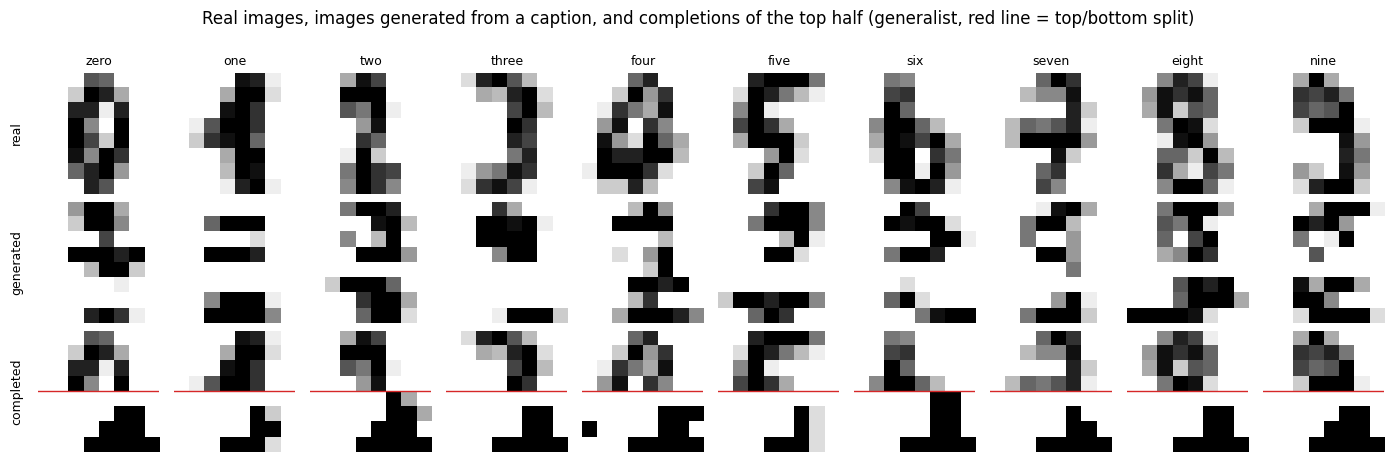

In [5]:
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
gen_imgs = res_gen["_gen"]; fills = res_gen["_fill"]
shown = {}
for j in range(200):
    d = int(y[te][j]) if j < 200 else None
    if d not in shown: shown[d] = j
for d in range(10):
    j = shown[d]
    axes[0, d].imshow(Xq[te][j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=15)
    axes[1, d].imshow(gen_imgs[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=15)
    axes[2, d].imshow(fills[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=15)
    axes[2, d].axhline(3.5, color="tab:red", lw=1)
    for r in range(3): axes[r, d].axis("off")
    axes[0, d].set_title(WORDS[d], fontsize=9)
axes[0, 0].text(-1.5, 3.5, "real", rotation=90, va="center", ha="right", fontsize=9)
axes[1, 0].text(-1.5, 3.5, "generated", rotation=90, va="center", ha="right", fontsize=9)
axes[2, 0].text(-1.5, 3.5, "completed", rotation=90, va="center", ha="right", fontsize=9)
plt.suptitle("Real images, images generated from a caption, and completions of the top half (generalist, red line = top/bottom split)", y=1.0)
plt.tight_layout(); plt.show()

**Lectura / reading: what the numbers show.** At equal model size and equal number of gradient steps, the generalist was **worse than the single-task models on every task** in this run: classification about 79 percent against 90, caption exact match about 64 against 84, completion about 40 against 57 percent recognised. The largest gap is **image generation from a caption**: the generalist's images were recognised as the requested digit about 8 percent of the time, which is at or below chance (10 percent), while the single-task generator reached about 62 percent (the ceiling set by the judge on real images is 97.6 percent, so even the specialist's images are only partly recognisable). In the figure the generalist's images (middle row) are dark strokes with no clear digit shape, and its completions (bottom row, below the red line, the top half being real) are nearly the same blob whatever the digit. Completion needs a caveat: copying the average bottom half, with no model at all, already gets about 54 percent, so the single-task completion model (about 57 percent) adds little over the visible top half at this training length.

What this does **not** show: that generalists are worse in general. The comparison is compute-matched, so the generalist received about a quarter of the gradient signal per task; the model has only 30 thousand parameters, so there is little spare capacity to share; and 500 steps are far from convergence. We cannot separate *interference between tasks* from *simple under-training* with this experiment (Exercises 2 and 3 are the next steps). What it does show is the measured trade-off at toy scale: sharing weights is not free, and the claims in the literature that mixing tasks helps rest on much larger models and much longer training. The gap in generation is also a reminder that the hardest template (a 64-token answer from a three-word prompt) is the first to suffer when capacity or training is scarce.

**Real systems.** A real multimodal model can be tried in a few lines with a pre-trained checkpoint, but it needs a download of hundreds of megabytes and far more CPU time than this module's budget, so the cell below is **shown, not executed**. It asks an open vision-language model to caption an image and answer a question about it, which is the same pair of templates (captioning, question answering) as our toy, at a vastly larger scale.

```python
# NOT EXECUTED in this notebook (needs `pip install transformers pillow` and a ~1 GB download).
from transformers import pipeline
from PIL import Image
captioner = pipeline("image-to-text", model="Salesforce/blip-image-captioning-base")
print(captioner(Image.open("photo.jpg")))                      # captioning template
vqa = pipeline("visual-question-answering", model="dandelin/vilt-b32-finetuned-vqa")
print(vqa(image=Image.open("photo.jpg"), question="How many people are in the picture?"))
```

The models are [BLIP](https://arxiv.org/abs/2201.12086) and [ViLT](https://arxiv.org/abs/2102.03334), both open and small by current standards.

## 9. Hands-on: a small scaling experiment

Now the experiment behind section 2. We train the generalist (all four templates) at **five sizes** (from about 2 thousand to 65 thousand parameters) with **two seeds**, 300 steps each, and measure the **held-out loss** (answer-token cross-entropy on the 497 test images, all four templates). We then fit a power law $L = a\,N^{-b}$ ($N$ = parameters, $a$ and $b$ fitted constants, $b$ the exponent) by least squares on $\log L$ against $\log N$, using only the **four smallest** sizes. We predict the loss of the fifth, largest size with a 90 percent prediction interval, and only then compare with the loss we really measure there. Two seeds give eight points for the fit.

In [6]:
SIZES = [(8, 1), (16, 1), (24, 2), (32, 2), (40, 3)]      # (width, layers); the last is held out of the fit
SEEDS = [0, 1]
t = time.time()
scale = {}   # (size index, seed) -> (parameters, held-out loss)
for i, (dm, nl) in enumerate(SIZES):
    for s in SEEDS:
        m = train([0, 1, 2, 3], dm=dm, nl=nl, steps=300, bs=32, lr=3e-3, seed=s)
        scale[(i, s)] = (nparams(m), test_loss(m, [0, 1, 2, 3]))
    print(f"size {i}: width {dm}, layers {nl}, {scale[(i, 0)][0]:,} parameters, "
          f"loss seeds {[round(scale[(i, s)][1], 3) for s in SEEDS]}")
print(f"scaling runs took {time.time()-t:.0f} s")

size 0: width 8, layers 1, 2,027 parameters, loss seeds [1.934, 1.949]


size 1: width 16, layers 1, 5,555 parameters, loss seeds [1.76, 1.727]


size 2: width 24, layers 2, 17,843 parameters, loss seeds [1.428, 1.422]


size 3: width 32, layers 2, 29,923 parameters, loss seeds [1.327, 1.232]


size 4: width 40, layers 3, 64,795 parameters, loss seeds [1.199, 1.141]
scaling runs took 493 s


fit on 4 sizes x 2 seeds: L = 6.49 * N^(-0.156), R^2 = 0.971
prediction at N = 64,795: 1.155  (90% prediction interval 1.067 to 1.250)
measured at N = 64,795: 1.199 and 1.141 (two seeds)
measured values inside the interval: True


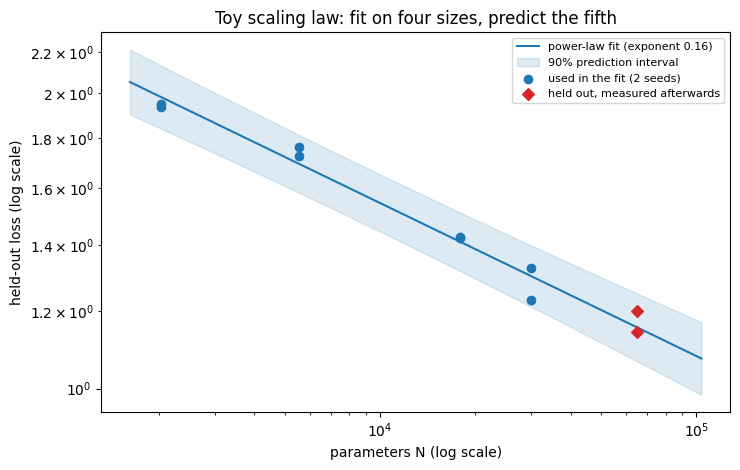

In [7]:
from scipy import stats
fit_pts = [(scale[(i, s)][0], scale[(i, s)][1]) for i in range(4) for s in SEEDS]
N = np.array([p[0] for p in fit_pts], float); Lo = np.array([p[1] for p in fit_pts])
lx, ly = np.log(N), np.log(Lo)
slope, icpt, r, _, _ = stats.linregress(lx, ly)
b, a = -slope, np.exp(icpt)
res = ly - (icpt + slope * lx); s_res = np.sqrt((res ** 2).sum() / (len(lx) - 2))
Nstar = scale[(4, 0)][0]; x0 = np.log(Nstar)
se_pred = s_res * np.sqrt(1 + 1 / len(lx) + (x0 - lx.mean()) ** 2 / ((lx - lx.mean()) ** 2).sum())
tq = stats.t.ppf(0.95, len(lx) - 2)
pred = np.exp(icpt + slope * x0); lo, hi = pred * np.exp(-tq * se_pred), pred * np.exp(tq * se_pred)
actual = [scale[(4, s)][1] for s in SEEDS]

print(f"fit on 4 sizes x 2 seeds: L = {a:.2f} * N^(-{b:.3f}), R^2 = {r**2:.3f}")
print(f"prediction at N = {Nstar:,}: {pred:.3f}  (90% prediction interval {lo:.3f} to {hi:.3f})")
print(f"measured at N = {Nstar:,}: {actual[0]:.3f} and {actual[1]:.3f} (two seeds)")
inside = all(lo <= v <= hi for v in actual)
print("measured values inside the interval:", inside)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
xs = np.logspace(np.log10(N.min() * 0.8), np.log10(Nstar * 1.6), 100)
ax.plot(xs, a * xs ** (-b), color="tab:blue", label=f"power-law fit (exponent {b:.2f})")
band_lo = np.exp(icpt + slope * np.log(xs)) * np.exp(-tq * s_res * np.sqrt(1 + 1/len(lx) + (np.log(xs) - lx.mean()) ** 2 / ((lx - lx.mean()) ** 2).sum()))
band_hi = np.exp(icpt + slope * np.log(xs)) * np.exp(tq * s_res * np.sqrt(1 + 1/len(lx) + (np.log(xs) - lx.mean()) ** 2 / ((lx - lx.mean()) ** 2).sum()))
ax.fill_between(xs, band_lo, band_hi, color="tab:blue", alpha=0.15, label="90% prediction interval")
ax.scatter(N, Lo, color="tab:blue", zorder=3, label="used in the fit (2 seeds)")
ax.scatter([Nstar] * 2, actual, color="tab:red", marker="D", zorder=3, label="held out, measured afterwards")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("parameters N (log scale)"); ax.set_ylabel("held-out loss (log scale)")
ax.set_title("Toy scaling law: fit on four sizes, predict the fifth")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Lectura / reading: what the numbers show.** Held-out loss fell smoothly as the model grew, from about 1.9 at 2 thousand parameters to about 1.2 at 65 thousand, and the two seeds agree closely at the small sizes (they differ by up to about 0.1 at 30 thousand parameters, a reminder that seed noise is not negligible). The power-law fit on the four smaller sizes has an exponent of about 0.16 and $R^2$ of about 0.97. It predicted a loss of about 1.16 at 65 thousand parameters with a 90 percent interval of about 1.07 to 1.25, and the two measured values (about 1.20 and 1.14) fall **inside** the interval. So in this toy, a short extrapolation worked. Be careful with how much that is worth: we extrapolated only a factor of about 2 in size, from eight points; the interval is wide (roughly plus or minus 8 percent); width and depth grew together, so the x axis mixes two ways of getting bigger; all models trained for the same 300 steps, so larger models may also simply learn faster per step rather than be better at convergence; and our exponent says nothing about language models, whose exponents are measured on completely different data.

**How far can such extrapolations be trusted?** Published scaling laws are fitted on runs spanning many orders of magnitude and are used to extrapolate by one or two orders of magnitude, where they have been checked against later training runs (see Kaplan et al. and Hoffmann et al. above). Even so: (1) the interval from a regression covers only the **noise inside the measured range**, not the chance that the trend bends outside it (our toy has a finite dataset, so larger models eventually overfit and the curve must flatten); (2) the fitted form (a pure power law without an irreducible-loss term) is a modelling choice, and different forms agree inside the data and disagree outside it; (3) the law predicts **loss**, not any particular ability (section 2). Treat an extrapolation as an informed hypothesis to be checked, never as a guarantee. Any forecast of *capabilities* from such curves is **speculation**.

## 10. Scaling alone: arguments for and against

The question "is scaling enough to reach general intelligence?" is open. Below are the strongest published arguments on each side. Neither list is a measurement of the answer; they are the reasons serious researchers give.

**Arguments that scaling (plus the existing recipe) may be enough.**

* *Smooth, predictable gains.* Loss improves as a power law over many orders of magnitude and the trend has not visibly broken so far ([Kaplan et al.](https://arxiv.org/abs/2001.08361), [Hoffmann et al.](https://arxiv.org/abs/2203.15556)).
* *The "bitter lesson".* [Sutton (2019)](http://www.incompleteideas.net/IncIdeas/BitterLesson.html) argues that, historically, general methods that exploit more computation have beaten hand-built knowledge.
* *Breadth appeared without being designed.* One next-token objective produced translation, coding and question answering ([Brown et al.](https://arxiv.org/abs/2005.14165)); this is the observation behind the "sparks" paper ([Bubeck et al.](https://arxiv.org/abs/2303.12712)).
* *Scale can be combined with new axes*: test-time compute and verifiable rewards (section 3) add capability beyond pre-training scale ([Snell et al.](https://arxiv.org/abs/2408.03314), [DeepSeek-R1](https://arxiv.org/abs/2501.12948)).

**Arguments that scaling alone is not enough.**

* *Different failure modes persist.* Compositional generalisation and planning errors remain ([Dziri et al.](https://arxiv.org/abs/2305.18654), [Valmeekam et al.](https://arxiv.org/abs/2206.10498)); hallucination has a theoretical reason to remain for facts seen rarely ([Kalai and Vempala](https://arxiv.org/abs/2311.14648)).
* *Efficiency.* [Chollet](https://arxiv.org/abs/1911.01547) argues that skill acquired from vast data is not the same as the ability to acquire skills from little; humans learn from few examples ([Lake et al.](https://arxiv.org/abs/1604.00289)).
* *Grounding.* [Bender and Koller (2020)](https://aclanthology.org/2020.acl-main.463/) argue that form alone, without grounding in the world, cannot yield meaning; [LeCun (2022)](https://openreview.net/forum?id=BZ5a1r-kVsf) argues that predicting tokens is the wrong objective for learning world models.
* *Resource limits.* High-quality human text is finite ([Villalobos et al.](https://arxiv.org/abs/2211.04325)) and recursive training on synthetic data has measured risks ([Shumailov et al.](https://arxiv.org/abs/2305.17493)).
* *No continual learning or autonomy built in* (section 6).

**What would change minds** is evidence that does not exist yet: either capability curves on efficiency-style tests such as ARC that keep rising smoothly with scale, or clear plateaus on them. Until then, the honest position is that both camps extrapolate from the same data. The most defensible *engineering* position is that scale, better data, reasoning methods, tools and new training signals all matter and are not exclusive.

## Key takeaways

* **One sequence model can serve many modalities** once everything is a token and a template tells it which task is asked. In our toy, the same weights classified, captioned, generated and completed digits.
* **Measure the comparison, do not assume it.** In our compute-matched toy (30 thousand parameters, 500 steps) the generalist was worse than the specialists on all four tasks, and failed at generation; that says nothing about large models, but it shows that weight sharing has a price that must be measured.
* **Scaling laws describe loss, not abilities.** Loss fell smoothly with size in our toy and a short extrapolation landed inside its interval, but extrapolating beyond the measured range is a hypothesis; the interval covers noise, not a change of trend.
* **Reasoning gains come from spending compute at answer time and from rewards that can be checked automatically**, strongest where a cheap verifier exists.
* **Agents, tools and world models extend the same idea** (more tokens, more modalities) toward actions and the physical world, with real-world limits on data and reliability.
* **"AGI" has no agreed definition** (Morris et al., Chollet, Legg and Hutter), benchmarks saturate and leak, and any date or probability for AGI mixes a contested definition with an unmeasurable forecast.
* **Whether scaling alone suffices is an open question**; keep measured results, arguments and speculation apart.

## Exercises

1. Retrain the generalist with a fifth template of your own, for example "caption then generate" (image, caption, then a second image), and measure whether the other four tasks get worse.
2. In section 8, train the generalist for 1000 steps instead of 500. Which task gains most, and does the gap to the single-task models change?
3. Repeat the generalist-versus-single-task comparison with three different seeds and report the mean and range. Is the sign of any difference stable?
4. Change the generation temperature from 0.5 to 0 (greedy) and to 1.0. How do the recognition rate and the diversity of the images change?
5. In section 9, add a sixth, larger size and refit using five sizes. Does the exponent change? Does the measured loss stay inside the new interval, or does overfitting bend the curve?
6. Fit instead $L = c + a\,N^{-b}$ with an irreducible term $c$ (use `scipy.optimize.curve_fit`) and compare its extrapolation with the pure power law.
7. Pick two of the AGI definitions in section 7 and write down one concrete test that one definition would pass and the other would fail, for a system of your choice.
8. For one of the arguments in section 10, find the paper's own stated limitations and add them to the list.

## References

All links were checked to resolve at the time of writing.

* Alayrac et al. (2022), Flamingo: a visual language model for few-shot learning. https://arxiv.org/abs/2204.14198
* Alpaydin and Kaynak, Optical Recognition of Handwritten Digits (UCI, CC BY 4.0). https://archive.ics.uci.edu/dataset/80
* Amodei et al. (2016), Concrete problems in AI safety. https://arxiv.org/abs/1606.06565
* Bender and Koller (2020), Climbing towards NLU. https://aclanthology.org/2020.acl-main.463/
* Brown et al. (2020), Language models are few-shot learners. https://arxiv.org/abs/2005.14165
* Bubeck et al. (2023), Sparks of artificial general intelligence. https://arxiv.org/abs/2303.12712
* Chameleon Team (2024), Chameleon: mixed-modal early-fusion foundation models. https://arxiv.org/abs/2405.09818
* Chollet (2019), On the measure of intelligence. https://arxiv.org/abs/1911.01547 ; ARC benchmark: https://github.com/fchollet/ARC-AGI ; https://arcprize.org/
* DeepSeek-AI (2025), DeepSeek-R1. https://arxiv.org/abs/2501.12948
* Dosovitskiy et al. (2020), An image is worth 16x16 words (ViT). https://arxiv.org/abs/2010.11929
* Dziri et al. (2023), Faith and fate: limits of transformers on compositionality. https://arxiv.org/abs/2305.18654
* Embodiment Collaboration (2023), Open X-Embodiment. https://arxiv.org/abs/2310.08864
* Ha and Schmidhuber (2018), World models. https://arxiv.org/abs/1803.10122
* Hafner et al. (2023), Mastering diverse domains through world models (DreamerV3). https://arxiv.org/abs/2301.04104
* Hoffmann et al. (2022), Training compute-optimal large language models. https://arxiv.org/abs/2203.15556
* Ji et al. (2023), Survey of hallucination in natural language generation. https://arxiv.org/abs/2202.03629
* Kalai and Vempala (2023), Calibrated language models must hallucinate. https://arxiv.org/abs/2311.14648
* Kaplan et al. (2020), Scaling laws for neural language models. https://arxiv.org/abs/2001.08361
* Kim et al. (2021), ViLT. https://arxiv.org/abs/2102.03334
* Kim et al. (2024), OpenVLA. https://arxiv.org/abs/2406.09246
* Kirkpatrick et al. (2017), Overcoming catastrophic forgetting in neural networks. https://arxiv.org/abs/1612.00796
* Kojima et al. (2022), Large language models are zero-shot reasoners. https://arxiv.org/abs/2205.11916
* Lake et al. (2016), Building machines that learn and think like people. https://arxiv.org/abs/1604.00289
* Legg and Hutter (2007), Universal intelligence: a definition of machine intelligence. https://arxiv.org/abs/0712.3329
* LeCun (2022), A path towards autonomous machine intelligence. https://openreview.net/forum?id=BZ5a1r-kVsf
* Li et al. (2022), BLIP. https://arxiv.org/abs/2201.12086
* Liang et al. (2022), Holistic evaluation of language models (HELM). https://arxiv.org/abs/2211.09110
* Liu et al. (2023), Lost in the middle. https://arxiv.org/abs/2307.03172
* Morris et al. (2023), Levels of AGI. https://arxiv.org/abs/2311.02462
* Ouyang et al. (2022), Training language models to follow instructions with human feedback. https://arxiv.org/abs/2203.02155
* Pedregosa et al. (2011), Scikit-learn. https://jmlr.org/papers/v12/pedregosa11a.html
* Radford et al. (2021), CLIP. https://arxiv.org/abs/2103.00020
* Radford et al. (2022), Whisper. https://arxiv.org/abs/2212.04356
* Ramesh et al. (2021), Zero-shot text-to-image generation (DALL-E). https://arxiv.org/abs/2102.12092
* Reed et al. (2022), A generalist agent (Gato). https://arxiv.org/abs/2205.06175
* Schaeffer et al. (2023), Are emergent abilities of large language models a mirage? https://arxiv.org/abs/2304.15004
* Schick et al. (2023), Toolformer. https://arxiv.org/abs/2302.04761
* Shumailov et al. (2023), The curse of recursion. https://arxiv.org/abs/2305.17493
* Snell et al. (2024), Scaling LLM test-time compute optimally. https://arxiv.org/abs/2408.03314
* Sutton (2019), The bitter lesson. http://www.incompleteideas.net/IncIdeas/BitterLesson.html
* Turing (1950), Computing machinery and intelligence. https://doi.org/10.1093/mind/LIX.236.433
* Valmeekam et al. (2022), PlanBench: an extensible benchmark for evaluating large language models on planning and reasoning about change. https://arxiv.org/abs/2206.10498
* van den Oord et al. (2017), Neural discrete representation learning (VQ-VAE). https://arxiv.org/abs/1711.00937
* Villalobos et al. (2022), Will we run out of data? https://arxiv.org/abs/2211.04325
* Wang et al. (2022), Self-consistency improves chain of thought reasoning. https://arxiv.org/abs/2203.11171
* Wei et al. (2022), Chain-of-thought prompting elicits reasoning. https://arxiv.org/abs/2201.11903
* Wei et al. (2022), Emergent abilities of large language models. https://arxiv.org/abs/2206.07682
* Yao et al. (2022), ReAct. https://arxiv.org/abs/2210.03629
* Zhang et al. (2024), A careful examination of large language model performance on grade school arithmetic. https://arxiv.org/abs/2405.00332
* Zitkovich et al. (2023), RT-2. https://arxiv.org/abs/2307.15818